# 07 — Todos os atributos × views, likes e comentários

Cada atributo do dataset é testado contra as 3 métricas com o teste adequado ao seu tipo:

| Tipo | Teste | Efeito em escala comum | Efeito de negócio |
|---|---|---|---|
| Categórico | Kruskal-Wallis | η² (% da variância explicada) | melhor vs. pior grupo (%) |
| Numérico | Spearman | ρ² (%) | quintil mais alto vs. mais baixo (%) |
| Alta cardinalidade (`creator_id`) | ANOVA | η² **acima do esperado por acaso** com 5 mil grupos | p90/p10 das médias por creator |
| Texto (legenda, hashtags, comentários) | TF-IDF + Ridge (CV) | R² de validação (%) | — |

Todos os p-values são corrigidos juntos (Benjamini-Hochberg). **MDE** = menor diferença (%) que o teste detectaria com 80% de poder.

In [1]:
# Setup: make solution/src importable and load the posts with derived features.
import sys
from pathlib import Path
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "solution" / "src").exists())
sys.path.insert(0, str(ROOT / "solution" / "src"))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from social_insights import data, top_performers as tp, clustering as cl, drivers as dr, audience as au, nlp, validation as va, plots

plots.apply_style()
pd.set_option("display.float_format", "{:.4f}".format)
df = data.load_posts(ROOT)
print(f"{len(df):,} posts")

from social_insights import attribute_scan as sc
TARGETS = sc.TARGETS
table = sc.scan(df)
display(Markdown(f"**{len(table)} testes** · p < 0,05 sem correção: **{int((table.p_value < 0.05).sum())}** "
                 f"(esperado por acaso: {len(table) * 0.05:.0f}) · significativos após correção: **{int(table.significativo.sum())}**"))
display(Markdown("**Atributos fora da varredura (e por quê):**"))
sc.skipped_attributes()

52,214 posts


**96 testes** · p < 0,05 sem correção: **5** (esperado por acaso: 5) · significativos após correção: **0**

**Atributos fora da varredura (e por quê):**

,motivo
atributo,
content_id,identificador único por post (sem grupos para ...
id,sequencial na ordem cronológica: equivale a po...
creator_name,muda a cada post do mesmo creator (~10 nomes p...
sponsor_name,"1,2 post por patrocinador em média (grupos peq..."
content_url,texto de URL gerado; testado via url_tld e url...
interactions / eng_rate_views,derivados das próprias métricas-alvo (vazamento)


## 1. Mapa geral: quanto cada atributo explica de cada métrica?

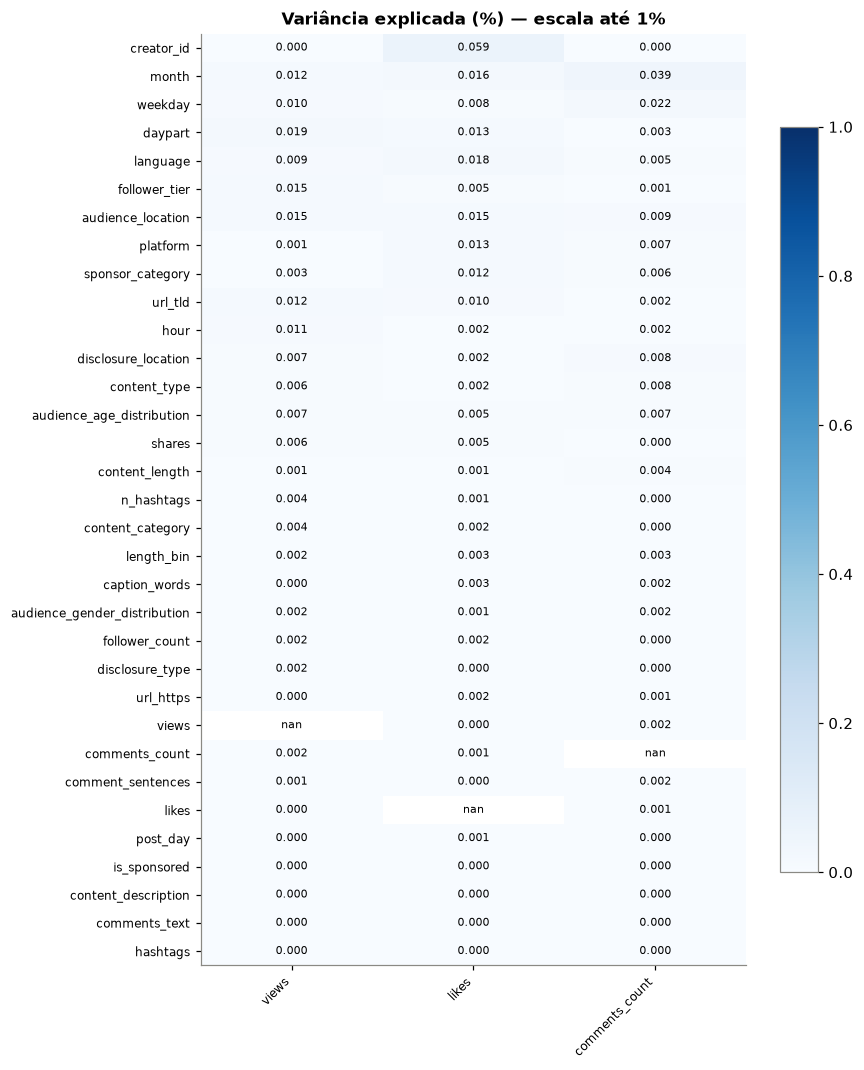

In [2]:
matrix = sc.summary_matrix(table)[TARGETS]
matrix = matrix.loc[matrix.max(axis=1).sort_values(ascending=False).index]
fig, ax = plt.subplots(figsize=(8, 11))
plots.heatmap(ax, matrix, "Variância explicada (%) — escala até 1%", cmap="Blues", vmin=0, vmax=1, fmt="{:.3f}")
plt.show()

**Leitura:** o maior valor do mapa é **0,06%** da variância (creator_id × likes, e mesmo esse está dentro do acaso, p = 0,37). A escala vai até 1%, e todo o mapa fica branco.
Para comparação: em dados reais de redes sociais, seguidores sozinhos costumam explicar 20–50% da variância das views.

## 2. Ranking por métrica (os 10 atributos com maior efeito aparente)

In [3]:
COLS = ["atributo", "tipo", "variância explicada (%)", "efeito de negócio (%)", "MDE (%)", "leitura do efeito", "p_value", "q_value"]
for t in TARGETS:
    display(Markdown(f"### {t}"))
    display(table[table.alvo == t][COLS].head(10).style.format(
        {"variância explicada (%)": "{:.4f}", "efeito de negócio (%)": "{:+.3f}", "MDE (%)": "{:.3f}", "p_value": "{:.3f}", "q_value": "{:.3f}"}, na_rep="—"))

### views

,atributo,tipo,variância explicada (%),efeito de negócio (%),MDE (%),leitura do efeito,p_value,q_value
64,daypart,categórico,0.0188,+0.032,0.034,melhor madrugada vs. pior tarde,0.014,0.704
65,follower_tier,categórico,0.0150,+0.106,0.131,melhor micro (10–50K) vs. pior nano (<10K),0.190,1.000
66,audience_location,categórico,0.0147,+0.029,0.048,melhor Germany vs. pior Brazil,0.297,1.000
67,month,categórico,0.0125,+0.042,0.060,melhor April vs. pior December,0.787,1.000
68,url_tld,categórico,0.0118,+0.036,0.042,melhor biz vs. pior net,0.236,1.000
69,hour,numérico,0.0114,-0.022,0.038,ρ = -0.0107 (quintil mais alto vs. mais baixo),0.015,0.704
70,weekday,categórico,0.0097,+0.025,0.045,melhor Wednesday vs. pior Friday,0.649,1.000
71,language,categórico,0.0095,+0.042,0.042,melhor Spanish vs. pior Japanese,0.280,1.000
72,disclosure_location,categórico,0.0068,+0.027,0.039,melhor caption vs. pior video,0.220,1.000
73,audience_age_distribution,categórico,0.0068,+0.024,0.058,melhor 13-18 vs. pior 26-35,0.524,1.000


### likes

,atributo,tipo,variância explicada (%),efeito de negócio (%),MDE (%),leitura do efeito,p_value,q_value
32,creator_id,alta cardinalidade,0.0591,+2.091,—,η² = 0.096 vs. 0.096 esperado por acaso (p90/p10 das médias por grupo),0.371,1.000
33,language,categórico,0.0183,+0.112,0.110,melhor Spanish vs. pior English,0.054,0.856
34,month,categórico,0.0162,+0.104,0.156,melhor December vs. pior October,0.700,1.000
35,audience_location,categórico,0.0149,+0.109,0.126,melhor UK vs. pior India,0.326,1.000
36,platform,categórico,0.0133,+0.086,0.100,melhor RedNote vs. pior Instagram,0.106,1.000
37,daypart,categórico,0.0133,+0.084,0.089,melhor manhã vs. pior tarde,0.035,0.743
38,sponsor_category,categórico,0.0124,+0.139,0.127,melhor cosmetics vs. pior fashion,0.326,1.000
39,url_tld,categórico,0.0103,+0.101,0.109,melhor biz vs. pior net,0.411,1.000
40,weekday,categórico,0.0077,+0.075,0.118,melhor Sunday vs. pior Wednesday,0.822,1.000
41,follower_tier,categórico,0.0049,+0.190,0.342,melhor micro (10–50K) vs. pior nano (<10K),0.650,1.000


### comments_count

,atributo,tipo,variância explicada (%),efeito de negócio (%),MDE (%),leitura do efeito,p_value,q_value
0,month,categórico,0.0391,+0.535,0.427,melhor June vs. pior January,0.038,0.743
1,weekday,categórico,0.0219,+0.302,0.324,melhor Friday vs. pior Tuesday,0.039,0.743
2,audience_location,categórico,0.0088,+0.215,0.345,melhor Russia vs. pior India,0.881,1.000
3,disclosure_location,categórico,0.0082,+0.212,0.277,melhor caption vs. pior video,0.108,1.000
4,content_type,categórico,0.0075,+0.206,0.296,melhor mixed vs. pior text,0.317,1.000
5,platform,categórico,0.0074,+0.190,0.273,melhor RedNote vs. pior YouTube,0.294,1.000
6,audience_age_distribution,categórico,0.0068,+0.170,0.410,melhor 19-25 vs. pior 36-50,0.425,1.000
7,sponsor_category,categórico,0.0063,+0.226,0.347,melhor food vs. pior gaming,0.774,1.000
8,language,categórico,0.0049,+0.153,0.300,melhor English vs. pior Hindi,0.610,1.000
9,content_length,numérico,0.0041,+0.180,0.273,ρ = +0.0064 (quintil mais alto vs. mais baixo),0.144,1.000


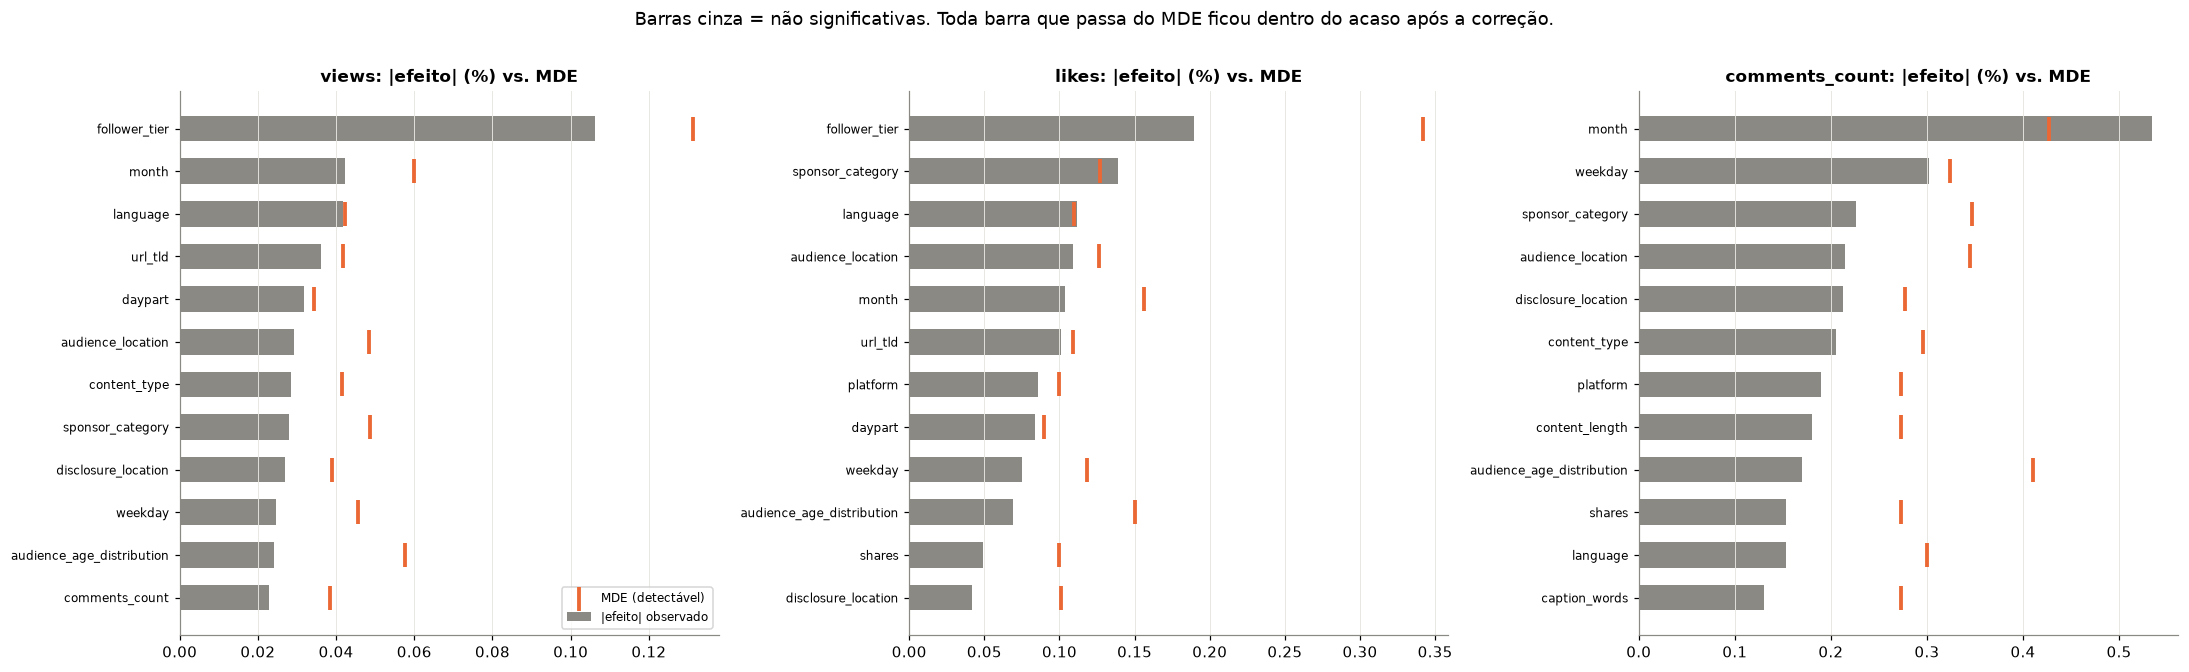

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(20, 6))
for ax, t in zip(axes, TARGETS):
    sub = table[(table.alvo == t) & table["efeito de negócio (%)"].notna() & (table.tipo != "alta cardinalidade")]
    sub = sub.sort_values("efeito de negócio (%)", key=abs).tail(12)
    y = np.arange(len(sub))
    ax.barh(y, sub["efeito de negócio (%)"].abs(), color=[plots.BLUE if s else plots.GRAY for s in sub["significativo"]], height=0.6, label="|efeito| observado")
    ax.scatter(sub["MDE (%)"], y, color=plots.ORANGE, marker="|", s=250, linewidths=2.5, label="MDE (detectável)", zorder=3)
    ax.set_yticks(y, sub["atributo"], fontsize=8); ax.set_title(f"{t}: |efeito| (%) vs. MDE"); ax.grid(axis="y", visible=False)
axes[0].legend(fontsize=8, loc="lower right")
fig.suptitle("Barras cinza = não significativas. Toda barra que passa do MDE ficou dentro do acaso após a correção.", y=1.01)
fig.tight_layout(); plt.show()

**Leitura:** os efeitos de negócio ficam entre 0,01% e 0,5%. Mesmo os que passam do MDE (ex.: mês × comentários, 0,53%) **não sobrevivem à correção para 96 testes**.
Note que 0,5% de 200 comentários é **1 comentário**.

## 3. Os "melhores aparentes" de perto

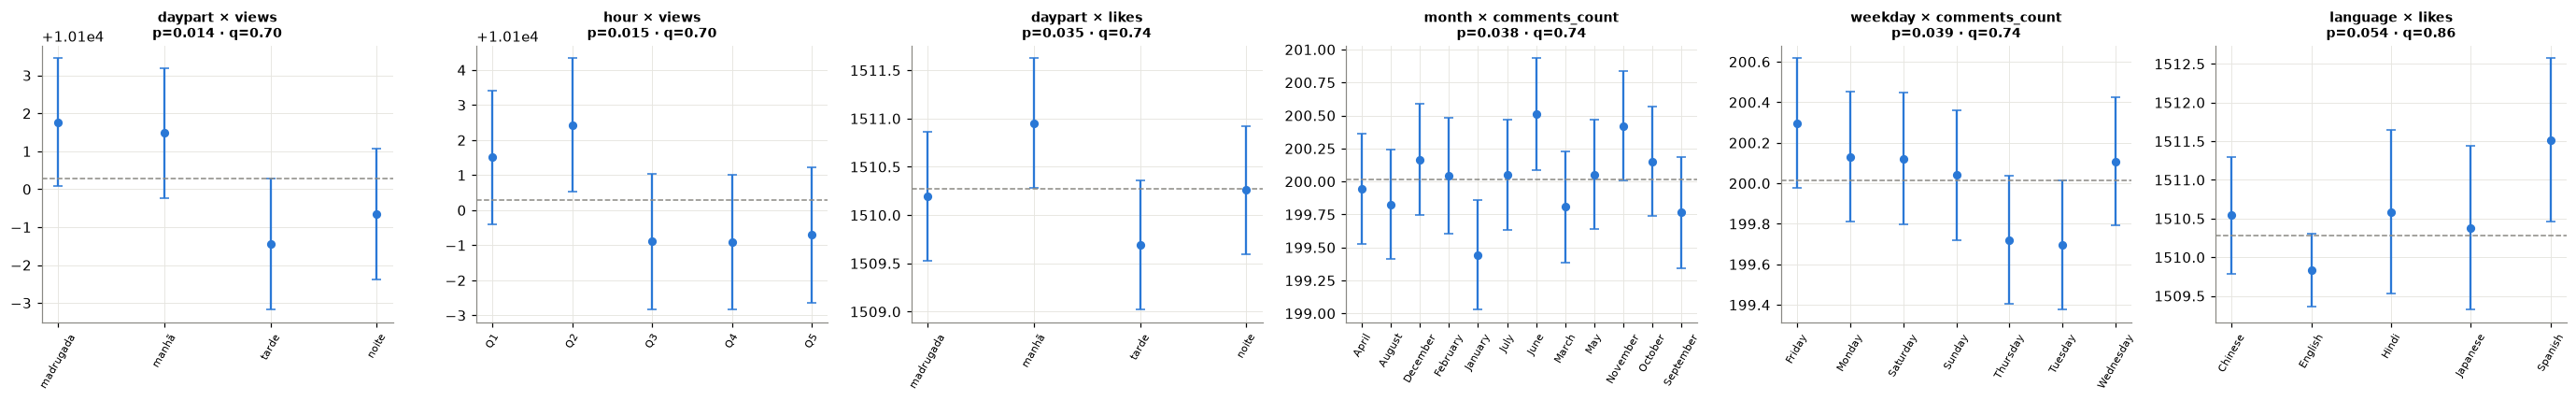

In [5]:
picks = table.sort_values("p_value").groupby("alvo").head(2)
picks = picks[picks.tipo.isin(["categórico", "numérico"])]
fig, axes = plt.subplots(1, len(picks), figsize=(4.2 * len(picks), 4), squeeze=False)
for ax, (_, row) in zip(axes[0], picks.iterrows()):
    prof = sc.group_profile(df, row["atributo"], row["alvo"])
    x = np.arange(len(prof))
    ax.errorbar(x, prof["mean"], yerr=prof["IC95"], fmt="o", color=plots.BLUE, capsize=3, markersize=5)
    ax.axhline(df[row["alvo"]].mean(), color=plots.GRAY, linestyle="--", linewidth=1)
    ax.set_xticks(x, [str(i)[:9] for i in prof.index], rotation=60, fontsize=7)
    ax.set_title(f"{row['atributo']} × {row['alvo']}\np={row['p_value']:.3f} · q={row['q_value']:.2f}", fontsize=9)
fig.tight_layout(); plt.show()

**Leitura:** os 2 atributos de menor p-value por métrica (ex.: período do dia × views, mês × comentários). As diferenças são de 1–3 views em 10.100 ou de ~1 comentário em 200, com ICs que quase tocam a média geral (tracejado).
São os candidatos que um relatório sem correção chamaria de "insight". Com 96 testes, ~5 passam de p < 0,05 por acaso, e foi o que aconteceu.

## 4. Relações entre as próprias métricas

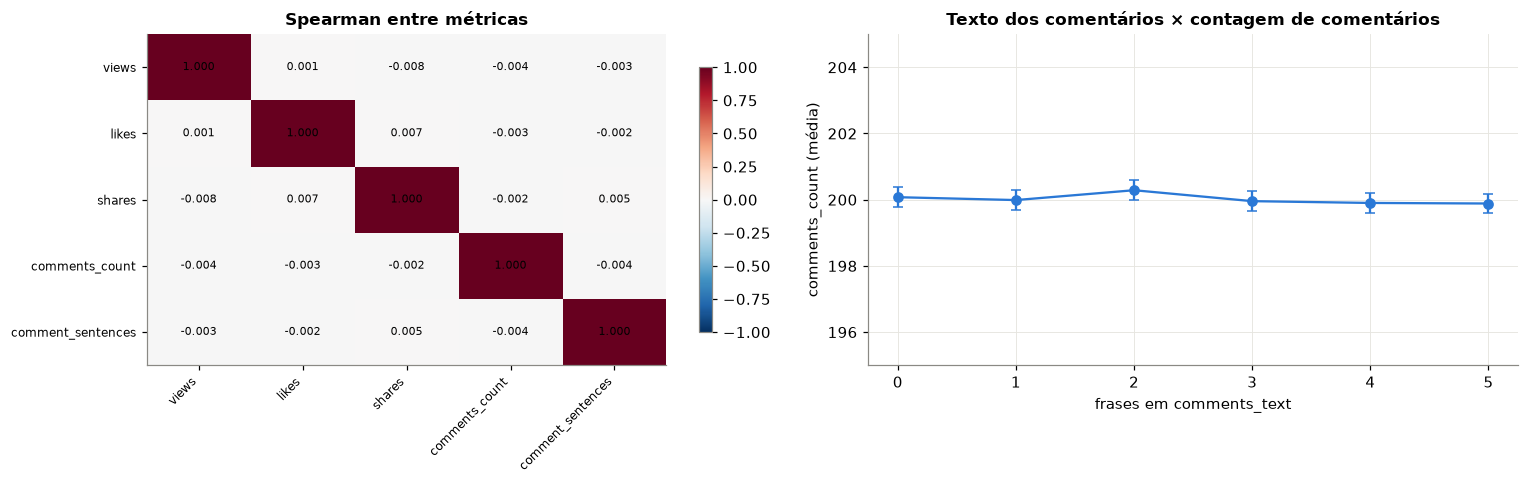

In [6]:
metrics = ["views", "likes", "shares", "comments_count"]
frame = sc.attribute_frame(df)
corr = frame[metrics + ["comment_sentences"]].corr("spearman")
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
plots.heatmap(axes[0], corr, "Spearman entre métricas", vmin=-1, vmax=1, fmt="{:.3f}")
g = frame.groupby("comment_sentences")["comments_count"].agg(["mean", "sem", "size"])
axes[1].errorbar(g.index, g["mean"], yerr=1.96 * g["sem"], fmt="o-", color=plots.BLUE, capsize=3)
axes[1].set_xlabel("frases em comments_text"); axes[1].set_ylabel("comments_count (média)")
axes[1].set_title("Texto dos comentários × contagem de comentários"); axes[1].set_ylim(195, 205)
fig.tight_layout(); plt.show()

**Leitura:**
- Views, likes, shares e comentários são **independentes entre si** (|ρ| < 0,01). Em redes reais, likes e comentários sobem junto com as views (ρ costuma passar de 0,7).
- **Inconsistência interna:** `comments_count` marca ~200 comentários por post, mas `comments_text` traz de 0 a 5 frases, sem relação nenhuma com a contagem. As colunas foram geradas separadamente.

## 5. Conclusão
1. **96 combinações atributo × métrica, 0 efeitos reais.** Nenhum atributo explica mais que 0,06% de views, likes ou comentários, e os ~5 "achados" sem correção são o acaso esperado.
2. Vale para **todos os tipos de atributo**: categóricos (plataforma, formato, audiência, tempo), numéricos (seguidores, duração, hashtags, horário, tendência no tempo), creator (5 mil creators sem diferença além do acaso) e textos (legenda, hashtags e comentários com R² ≤ 0).
3. **As métricas não se relacionam entre si**, nem o texto dos comentários com a contagem de comentários. Isso é a assinatura de um dataset gerado com cada coluna sorteada de forma independente.
4. **Método validado:** em testes com efeito plantado (plataforma, seguidores, creator e legenda), a varredura acusa o atributo certo (ver `solution/tests/test_attribute_scan.py`). Rodando com dados reais, este mesmo notebook vira o mapa de "o que move cada métrica".